## Clustering Iris

Installing package into 'C:/Users/ronan/AppData/Local/R/win-library/4.3'
(as 'lib' is unspecified)




  There is a binary version available (and will be installed) but the
  source version is later:
           binary source
factoextra  1.0.7  2.2.0



also installing the dependencies 'Deriv', 'microbenchmark', 'doBy', 'pbkrtest', 'car', 'rstatix', 'ggpubr'




package 'Deriv' successfully unpacked and MD5 sums checked
package 'microbenchmark' successfully unpacked and MD5 sums checked
package 'doBy' successfully unpacked and MD5 sums checked
package 'pbkrtest' successfully unpacked and MD5 sums checked
package 'car' successfully unpacked and MD5 sums checked
package 'rstatix' successfully unpacked and MD5 sums checked
package 'ggpubr' successfully unpacked and MD5 sums checked
package 'factoextra' successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\ronan\AppData\Local\Temp\RtmpwB06Jq\downloaded_packages


Warning message:
"package 'cluster' was built under R version 4.3.3"
Warning message:
"package 'factoextra' was built under R version 4.3.3"
Loading required package: ggplot2

Welcome! Want to learn more? See two factoextra-related books at https://goo.gl/ve3WBa



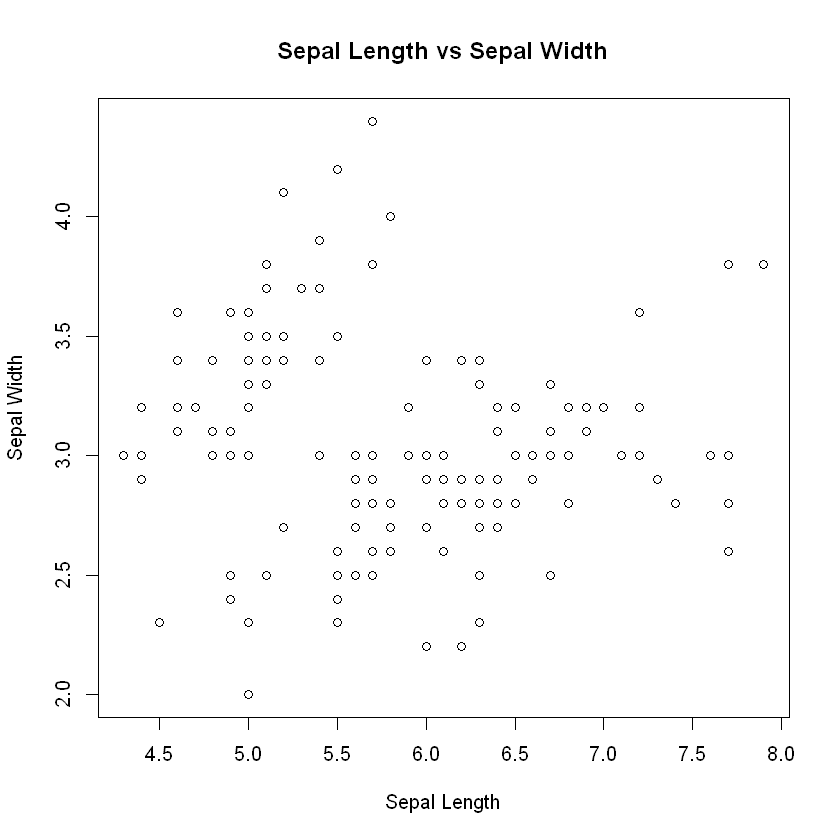

In [1]:
# Import libraries
install.packages("factoextra", type="binary")
library(cluster)
library(factoextra)

# Visualise the Data
plot(iris$Sepal.Length, 
iris$Sepal.Width, 
main = "Sepal Length vs Sepal Width", 
xlab = "Sepal Length", 
ylab = "Sepal Width")

### Hierarchical clustering

        
clusters setosa versicolor virginica
       1     49          0         0
       2      1         21         2
       3      0         29        48

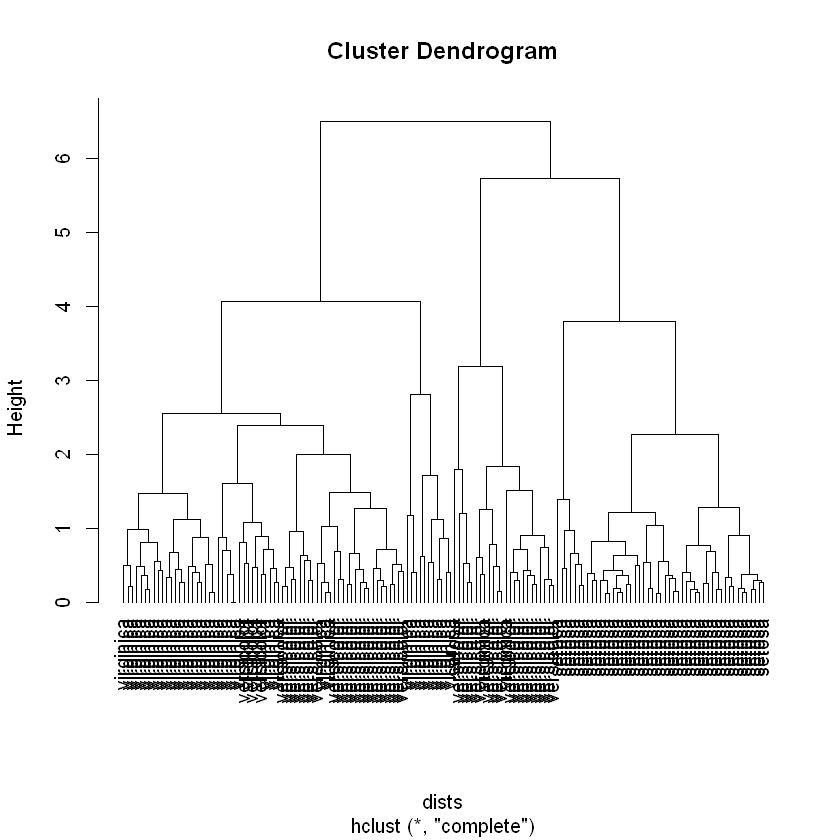

In [2]:
iris_scaled = scale(iris[,1:4])
dists = dist(iris_scaled, method = "euclidean")

# Hierarchical clustering with complete linkage
hc = hclust(dists, method = "complete")

# Dendrogram plot
plot(hc, labels = iris$Species, hang = -1)

# Cut tree into 3 clusters
clusters = cutree(hc, k = 3)

# Compare clusters with the actual species
table(clusters, iris$Species)

### K-Means Clustering

In [3]:
iris_1 <- iris[, -5]
set.seed(240)
kmeans.re <- kmeans(iris_1, centers = 3, nstart = 20)
kmeans.re

K-means clustering with 3 clusters of sizes 50, 62, 38

Cluster means:
  Sepal.Length Sepal.Width Petal.Length Petal.Width
1     5.006000    3.428000     1.462000    0.246000
2     5.901613    2.748387     4.393548    1.433871
3     6.850000    3.073684     5.742105    2.071053

Clustering vector:
  [1] 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 [38] 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 3 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 [75] 2 2 2 3 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 2 3 3 3 3 2 3 3 3 3
[112] 3 3 2 2 3 3 3 3 2 3 2 3 2 3 3 2 2 3 3 3 3 3 2 3 3 3 3 2 3 3 3 2 3 3 3 2 3
[149] 3 2

Within cluster sum of squares by cluster:
[1] 15.15100 39.82097 23.87947
 (between_SS / total_SS =  88.4 %)

Available components:

[1] "cluster"      "centers"      "totss"        "withinss"     "tot.withinss"
[6] "betweenss"    "size"         "iter"         "ifault"      

In [4]:
cm <- table(iris$Species, kmeans.re$cluster)
cm

            
              1  2  3
  setosa     50  0  0
  versicolor  0 48  2
  virginica   0 14 36

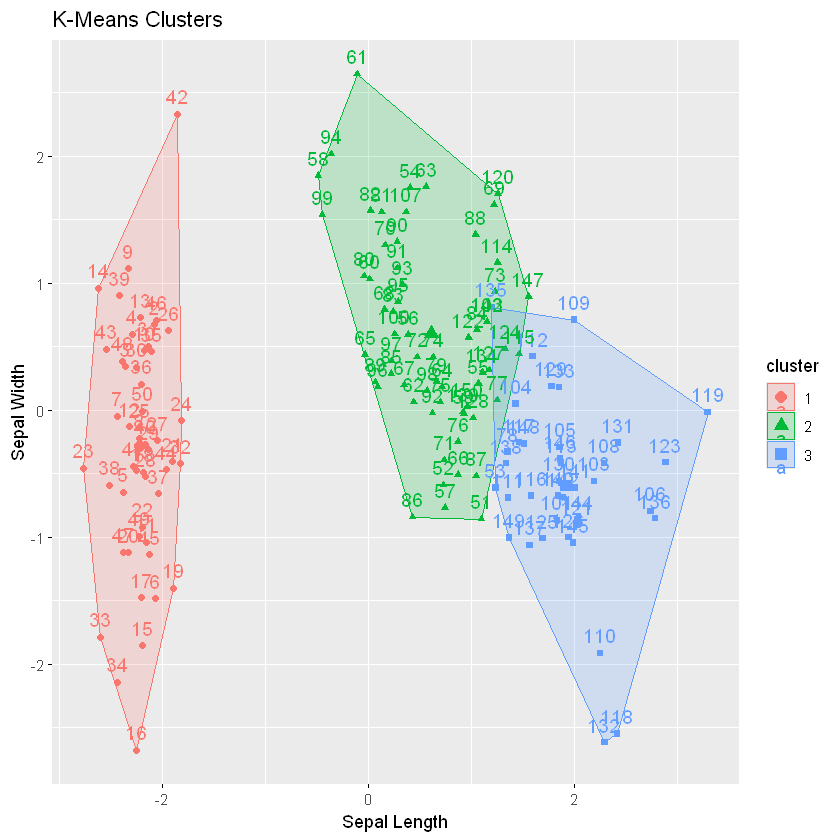

In [6]:
fviz_cluster(kmeans.re, data = iris_1, 
main = "K-Means Clusters", 
xlab = "Sepal Length", 
ylab = "Sepal Width")